# 03 · Trap 1: peeking at results early

The experiment platform shows a live dashboard with a p-value that updates every day.
Checking it is harmless. **Deciding** from it — "it's significant, ship it" — is not:
every look is another chance for noise to cross the line, and you only need one crossing.

This notebook (1) shows how fast the false-positive rate grows with the number of looks,
(2) compares two valid ways to look early — O'Brien-Fleming group-sequential boundaries
and always-valid mSPRT p-values — and (3) replays our real experiment to show what a
peeker would have shipped, and why even a valid sequential test would not have saved us.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from pizza_ab.simulate import load_or_simulate
from pizza_ab.metrics import dashboard_snapshot, user_metrics
from pizza_ab.stats import mean_test, obrien_fleming_bounds, msprt_always_valid_p
from pizza_ab.config import ENROLL_DAYS
from pizza_ab import plots

plots.set_style()
rng = np.random.default_rng(42)

## 1. How much does peeking inflate false positives?

Simulate A/A tests (no true effect) and test after each of K equally sized batches,
stopping at the first |z| > 1.96. Under H0, the cumulative z-statistic after k batches
is a scaled random walk, which is all we need to simulate.

In [2]:
def naive_fpr(n_looks, n_sims=20_000):
    z = np.cumsum(rng.standard_normal((n_sims, n_looks)), axis=1) / np.sqrt(np.arange(1, n_looks + 1))
    return (np.abs(z) > 1.96).any(axis=1).mean()

looks = [1, 2, 3, 5, 7, 10, 14, 21, 28, 50, 100]
fpr = pd.Series({k: naive_fpr(k) for k in looks}, name="false positive rate")
fpr.to_frame().T.style.format("{:.1%}")

,1,2,3,5,7,10,14,21,28,50,100
false positive rate,5.1%,8.4%,11.2%,14.3%,16.5%,19.6%,21.7%,24.9%,27.7%,31.8%,37.7%


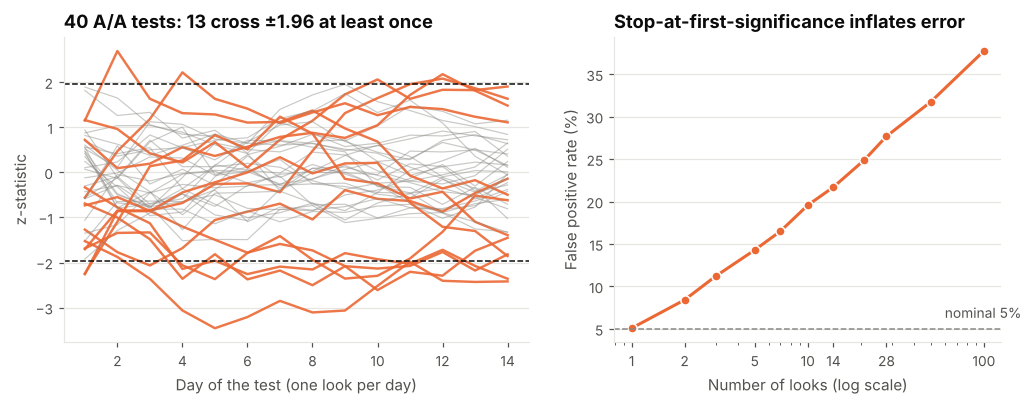

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})

ax = axes[0]
paths = np.cumsum(rng.standard_normal((40, ENROLL_DAYS)), axis=1) / np.sqrt(np.arange(1, ENROLL_DAYS + 1))
crossed = (np.abs(paths) > 1.96).any(axis=1)
for p, c in zip(paths, crossed):
    ax.plot(np.arange(1, ENROLL_DAYS + 1), p, color=plots.TREATMENT if c else plots.MUTED,
            lw=1.6 if c else 0.8, alpha=0.9 if c else 0.45)
for b in (1.96, -1.96):
    ax.axhline(b, color=plots.TEXT, lw=1, ls="--")
ax.set_xlabel("Day of the test (one look per day)")
ax.set_ylabel("z-statistic")
ax.set_title(f"40 A/A tests: {crossed.sum()} cross ±1.96 at least once")

ax = axes[1]
ax.plot(fpr.index, fpr.values * 100, "o-", color=plots.TREATMENT, ms=6, mec="white")
ax.axhline(5, color=plots.MUTED, lw=1, ls="--")
ax.text(60, 6.3, "nominal 5%", color=plots.TEXT_2, fontsize=9)
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 14, 28, 100], ["1", "2", "5", "10", "14", "28", "100"])
ax.set_xlabel("Number of looks (log scale)")
ax.set_ylabel("False positive rate (%)")
ax.set_title("Stop-at-first-significance inflates error")
plots.save(fig, "03_peeking_fpr");

Daily peeking over a 14-day test turns a 5% error rate into roughly **22%**. It keeps
climbing with more looks (≈ 38% at 100 looks). With enough looks, an A/A test will eventually "win".

## 2. Two valid ways to look early

**O'Brien-Fleming (OBF) group-sequential boundaries.** Fix the number of looks in advance
and demand very strong evidence early, relaxing toward ~2 at the end. The final
boundary is barely above 1.96, so a test that runs to the end loses almost no power.

**mSPRT always-valid p-values** (Johari et al., *Peeking at A/B Tests*, 2017). The
p-value is valid at *any* stopping time, even continuously. The price is power: it needs
a guess of the effect scale (τ) and is more conservative than OBF at the final look.

In [4]:
K = ENROLL_DAYS
obf = obrien_fleming_bounds(K)
pd.DataFrame({"look": np.arange(1, K + 1), "OBF |z| boundary": obf,
              "nominal p at boundary": 2 * norm.sf(obf)}
             ).set_index("look").T.style.format("{:.3f}")

look,1,2,3,4,5,6,7,8,9,10,11,12,13,14
OBF |z| boundary,7.879,5.571,4.549,3.939,3.524,3.217,2.978,2.786,2.626,2.492,2.376,2.274,2.185,2.106
nominal p at boundary,0.000,0.000,0.000,0.000,0.000,0.001,0.003,0.005,0.009,0.013,0.018,0.023,0.029,0.035


Simulate tests sized like ours: 14 equal looks, each adding ~4,480 users per arm, with the
historical baseline conversion. This is a stylized version of our design. In the real test,
look k is the moment the k-th enrollment cohort's 7-day window closes, i.e. calendar day k + 6,
so look 14 is the day-20/21 read-out. Results below are in **looks**, not calendar days.
First with no effect (false positive rate), then with a true 5% lift (power and how early each
method stops).

In [5]:
hist_users, hist_orders = load_or_simulate("historical")
p0 = user_metrics(hist_users, hist_orders)["converted"].mean()   # same baseline as notebook 01
n_day, tau = 4_480, 0.0057                                       # tau ≈ the absolute MDE

def run(lift, n_sims=5_000):
    out = {"naive": [], "fixed": [], "obf": [], "msprt": []}
    stop = {"obf": [], "msprt": []}
    for _ in range(n_sims):
        xc = np.cumsum(rng.binomial(n_day, p0, K))
        xt = np.cumsum(rng.binomial(n_day, p0 * (1 + lift), K))
        n = n_day * np.arange(1, K + 1)
        pc, pt = xc / n, xt / n
        var = pc * (1 - pc) / n + pt * (1 - pt) / n
        z = (pt - pc) / np.sqrt(var)
        out["naive"].append((np.abs(z) > 1.96).any())
        out["fixed"].append(abs(z[-1]) > 1.96)
        hit = np.abs(z) > obf
        out["obf"].append(hit.any()); stop["obf"].append(np.argmax(hit) + 1 if hit.any() else K)
        avp = msprt_always_valid_p(pt - pc, var, tau)
        hit = avp < 0.05
        out["msprt"].append(hit.any()); stop["msprt"].append(np.argmax(hit) + 1 if hit.any() else K)
    return ({k: np.mean(v) for k, v in out.items()}, {k: np.mean(v) for k, v in stop.items()})

h0, _ = run(0.0)
h1, stop1 = run(0.05)
comparison = pd.DataFrame({
    "false positive rate (A/A)": h0,
    "power (true +5% lift)": h1,
    "avg. stopping look of 14 (true +5%)": {"naive": np.nan, "fixed": K, **stop1},
}).rename(index={"naive": "naive peeking at every look", "fixed": "fixed horizon (look 14 only)",
                 "obf": "O'Brien-Fleming, 14 looks", "msprt": "mSPRT, always valid"})
comparison.style.format({"false positive rate (A/A)": "{:.1%}", "power (true +5% lift)": "{:.1%}",
                         "avg. stopping look of 14 (true +5%)": "{:.1f}"}, na_rep="—")

,false positive rate (A/A),power (true +5% lift),avg. stopping look of 14 (true +5%)
naive peeking at every look,21.0%,92.7%,—
fixed horizon (look 14 only),4.9%,88.2%,14.0
"O'Brien-Fleming, 14 looks",4.8%,87.0%,9.9
"mSPRT, always valid",0.9%,61.3%,10.7


* Naive peeking: high "power", but a false-positive rate about 4× the promise. The power
  is fake — it comes from the same flaw.
* OBF holds the 5% error rate (4.8% here; with 5,000 runs expect ±0.6 pp of simulation noise)
  and keeps nearly all the fixed-horizon power, while stopping about 4 looks early on average
  when the effect is real (look ~10 ≈ calendar day 16 instead of 20).
* mSPRT keeps the error rate *below* 5% under any stopping rule, at a cost in power.
  Use it when people will look continuously no matter what you say; use OBF when you can
  commit to a schedule.

## 3. Replay our experiment

### What the live dashboard showed
The dashboard computes "converted so far" for everyone enrolled so far. Note that this
metric itself is different from the pre-registered one: day-1 users have had 1 day to order,
day-0 users have had 14. That alone makes early dashboard numbers non-comparable to the
final read-out.

In [6]:
users, orders = load_or_simulate("experiment")
dash = []
for d in range(0, 21):
    snap = dashboard_snapshot(users, orders, d)
    r = mean_test(snap.loc[snap.variant == "control", "converted"],
                  snap.loc[snap.variant == "treatment", "converted"])
    dash.append({"day": d, "users": len(snap), "lift": r.rel_lift, "lo": r.rel_ci[0],
                 "hi": r.rel_ci[1], "p": r.p_value})
dash = pd.DataFrame(dash).set_index("day")
first_sig = dash.index[dash["p"] < 0.05][0]
print(f"First day the dashboard shows p < 0.05: day {first_sig}  "
      f"(lift {dash.loc[first_sig, 'lift']:+.1%}, n = {dash.loc[first_sig, 'users']:,})")
dash.head(8).style.format({"users": "{:,}", "lift": "{:+.1%}", "lo": "{:+.1%}", "hi": "{:+.1%}", "p": "{:.3f}"})

First day the dashboard shows p < 0.05: day 1  (lift +23.8%, n = 17,809)


,users,lift,lo,hi,p
day,,,,,
0,"8,963",+18.3%,-21.2%,+57.8%,0.325
1,"17,809",+23.8%,-0.1%,+47.7%,0.030
2,"26,798",+19.2%,+2.9%,+35.4%,0.012
3,"35,911",+11.4%,-0.1%,+22.9%,0.040
4,"44,700",+9.6%,+1.1%,+18.1%,0.020
5,"53,729",+7.3%,+0.7%,+13.9%,0.025
6,"62,723",+5.8%,-0.0%,+11.6%,0.046
7,"71,639",+5.0%,-0.3%,+10.3%,0.058


A peeker who ships at the first p < 0.05 ships on **day 1**, with 14% of the planned sample,
reporting a **+24% lift** — three times the day-21 estimate.

(Small print: on day 1 the relative-lift CI touches 0 while p = 0.03. The p-value tests the
absolute difference; the relative CI also carries the uncertainty of the control mean in
its denominator. At the boundary the two can disagree slightly.)

### A valid sequential test on the pre-registered metric
Use only users whose 7-day window has closed. Look k (k = 1..14) includes enrollment
cohorts 0..k−1, so information grows evenly, which is what the OBF boundaries assume.

In [7]:
m = user_metrics(users, orders)
seq = []
for k in range(1, K + 1):
    sub = m[m["enroll_day"] < k]
    c, t = sub[sub.variant == "control"], sub[sub.variant == "treatment"]
    r = mean_test(c["converted"], t["converted"])
    var = c["converted"].var() / len(c) + t["converted"].var() / len(t)
    seq.append({"look": k, "calendar_day": k + 6, "lift": r.rel_lift, "diff": r.diff, "var": var,
                "z": r.diff / np.sqrt(var), "obf_bound": obf[k - 1]})
seq = pd.DataFrame(seq).set_index("look")
seq["msprt_p"] = msprt_always_valid_p(seq["diff"], seq["var"], tau)
obf_stop = seq.index[np.abs(seq["z"]) > seq["obf_bound"]][0]
msprt_stop = seq.index[seq["msprt_p"] < 0.05][0]
print(f"OBF would stop at look {obf_stop} (calendar day {seq.loc[obf_stop, 'calendar_day']}), "
      f"lift {seq.loc[obf_stop, 'lift']:+.1%}")
print(f"mSPRT would stop at look {msprt_stop} (calendar day {seq.loc[msprt_stop, 'calendar_day']}), "
      f"lift {seq.loc[msprt_stop, 'lift']:+.1%}")

OBF would stop at look 8 (calendar day 14), lift +6.6%
mSPRT would stop at look 8 (calendar day 14), lift +6.6%


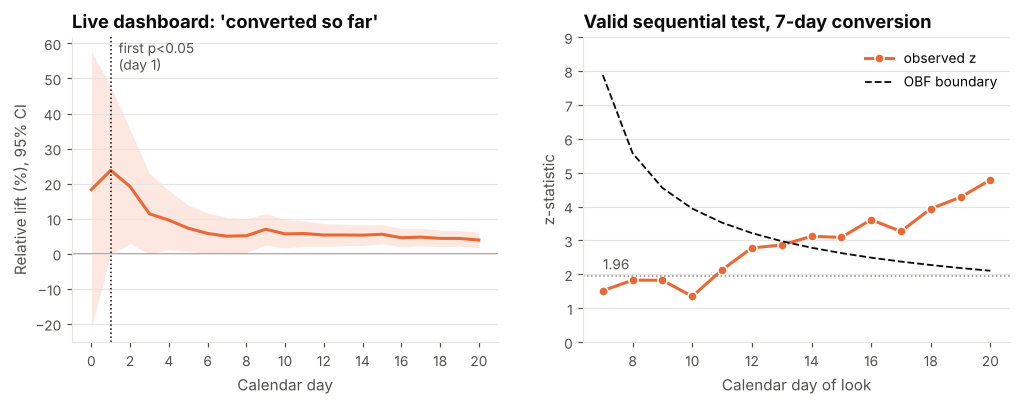

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.fill_between(dash.index, dash["lo"] * 100, dash["hi"] * 100, color=plots.TREATMENT, alpha=0.15, lw=0)
ax.plot(dash.index, dash["lift"] * 100, color=plots.TREATMENT)
ax.axvline(first_sig, color=plots.TEXT, lw=1, ls=":")
ax.text(first_sig + 0.4, ax.get_ylim()[1] * 0.85 if ax.get_ylim()[1] > 0 else 1,
        f"first p<0.05\n(day {first_sig})", fontsize=9, color=plots.TEXT_2)
plots.zero_line(ax)
ax.set_xticks(range(0, 21, 2))
ax.set_xlabel("Calendar day")
ax.set_ylabel("Relative lift (%), 95% CI")
ax.set_title("Live dashboard: 'converted so far'")

ax = axes[1]
ax.plot(seq["calendar_day"], seq["z"], "o-", color=plots.TREATMENT, ms=6, mec="white", label="observed z")
ax.plot(seq["calendar_day"], seq["obf_bound"], color=plots.TEXT, lw=1.2, ls="--", label="OBF boundary")
ax.axhline(1.96, color=plots.MUTED, lw=1, ls=":")
ax.text(seq["calendar_day"].iloc[0], 2.15, "1.96", color=plots.TEXT_2, fontsize=9)
ax.set_ylim(0, 9)
ax.set_xlabel("Calendar day of look")
ax.set_ylabel("z-statistic")
ax.set_title("Valid sequential test, 7-day conversion")
ax.legend(loc="upper right")
plots.save(fig, "03_replay");

## 4. What this means for our decision

* The dashboard turned "significant" on day 1 at +24%, with 14% of the planned sample. The
  final pre-registered estimate is +7.6%. Stopping at the first significant
  look selects for overestimates (the *winner's curse*, or Type M error).
* The OBF test would also stop early here — at look 8 (calendar day 14) with +6.6% —
  legitimately. The 7-day conversion lift is
  real **for the metric we measured**.
* But notice what sequential testing does **not** fix: it guarantees the error rate for
  the metric you test; it says nothing about whether that metric means the same thing in
  week 4 as in week 1. Every user in the primary metric is in their first week with a
  brand-new design. Stopping early makes this worse: early looks contain only first-week
  behaviour. **That is the next trap — notebook 04.**

**Rule we follow:** look as often as you like, but decide only at a pre-registered look
with a pre-registered boundary. If stakeholders will act on the live dashboard anyway,
make the dashboard show always-valid p-values instead of naive ones.